<a href="https://colab.research.google.com/github/gerenciaracemachine-cpu/regresiones-lineales/blob/main/Red_Neuronal_Race_Machine_20_oct.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(42)

In [2]:
num_muestras = 500


km_diario = np.random.uniform(10, 120, num_muestras)
dias_ultimo_cambio = np.random.uniform(10, 180, num_muestras)
gasto_acumulado = np.random.uniform(50, 400, num_muestras)


score = (km_diario * 0.04) + (dias_ultimo_cambio * 0.03) - 3.5
probabilidad = 1 / (1 + np.exp(-score))  #
y = (probabilidad > 0.5).astype(int)


X_raw = np.column_stack((km_diario, dias_ultimo_cambio, gasto_acumulado))
X = (X_raw - X_raw.min(axis=0)) / (X_raw.max(axis=0) - X_raw.min(axis=0))
y = y.reshape(-1, 1)

print(f"Dataset creado exitosamente con {num_muestras} clientes.")
print(f"Forma de X: {X.shape} | Forma de y: {y.shape}")

Dataset creado exitosamente con 500 clientes.
Forma de X: (500, 3) | Forma de y: (500, 1)


In [3]:

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)


def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return (x > 0).astype(float)

In [4]:

input_dim = 3
hidden_dim = 6
output_dim = 1


W1 = np.random.randn(input_dim, hidden_dim) * 0.01
b1 = np.zeros((1, hidden_dim))

W2 = np.random.randn(hidden_dim, output_dim) * 0.01
b2 = np.zeros((1, output_dim))

In [8]:
learning_rate = 0.1
epochs = 2000
loss_history = []

for epoch in range(epochs):

    Z1 = np.dot(X, W1) + b1
    A1 = relu(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)


    loss = np.mean((y - A2) ** 2)
    loss_history.append(loss)


    dZ2 = (A2 - y) * sigmoid_derivative(Z2)
    dW2 = np.dot(A1.T, dZ2) / num_muestras
    db2 = np.sum(dZ2, axis=0, keepdims=True) / num_muestras


    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * relu_derivative(Z1)
    dW1 = np.dot(X.T, dZ1) / num_muestras
    db1 = np.sum(dZ1, axis=0, keepdims=True) / num_muestras


    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    if epoch % 200 == 0:
        print(f"Época {epoch} - Pérdida (Loss): {loss:.4f}")

Época 0 - Pérdida (Loss): 0.1524
Época 200 - Pérdida (Loss): 0.1489
Época 400 - Pérdida (Loss): 0.1440
Época 600 - Pérdida (Loss): 0.1376
Época 800 - Pérdida (Loss): 0.1295
Época 1000 - Pérdida (Loss): 0.1200
Época 1200 - Pérdida (Loss): 0.1095
Época 1400 - Pérdida (Loss): 0.0988
Época 1600 - Pérdida (Loss): 0.0885
Época 1800 - Pérdida (Loss): 0.0791


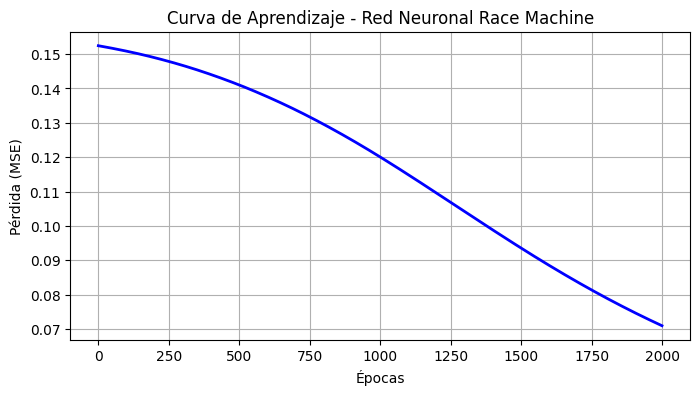


Exactitud final del modelo: 91.20%


In [9]:

plt.figure(figsize=(8, 4))
plt.plot(loss_history, color='blue', linewidth=2)
plt.title('Curva de Aprendizaje - Red Neuronal Race Machine')
plt.xlabel('Épocas')
plt.ylabel('Pérdida (MSE)')
plt.grid(True)
plt.show()


predicciones = (A2 > 0.5).astype(int)
accuracy = np.mean(predicciones == y) * 100
print(f"\nExactitud final del modelo: {accuracy:.2f}%")

In [10]:
cliente_nuevo = np.array([[90, 120, 250]])


cliente_norm = (cliente_nuevo - X_raw.min(axis=0)) / (X_raw.max(axis=0) - X_raw.min(axis=0))


z1_nuevo = np.dot(cliente_norm, W1) + b1
a1_nuevo = relu(z1_nuevo)
z2_nuevo = np.dot(a1_nuevo, W2) + b2
prob_retorno = sigmoid(z2_nuevo)[0][0]

print(f"Probabilidad de retorno para el nuevo cliente: {prob_retorno * 100:.1f}%")
if prob_retorno > 0.5:
    print("Resultado: Se debe enviar notificación de recordatorio de servicio por WhatsApp.")
else:
    print("Resultado: Cliente al día / no requiere mantenimiento urgente.")

Probabilidad de retorno para el nuevo cliente: 95.2%
Resultado: Se debe enviar notificación de recordatorio de servicio por WhatsApp.
